# Evaluate one trained run
Loss history, per-mask validation loss, and samples of the run (here, or on a GPU with `tests/slurm/sample_fm.sbatch`):
E3 joint distribution, E4 inputs -> observables, E5 inputs given Omega / m_h, E6 electroweakino masses and Omega.
The helpers come from `v2_fm_pmssm.training` (as in `compare_fm.ipynb`).
Workflow: `sample_mode = "save"` -> `sbatch tests/slurm/sample_fm.sbatch <run>` -> `sample_mode = "load"`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pycirclize import Circos

from v2_fm_pmssm.data import load_data, transform
from v2_fm_pmssm.training import (load_run, generate, to_physical, make_job,
                                  plot_marginals, plot_corner, plot_pred_vs_truth)

/u/yinya/workspace/multi_modal_pMSSM/v2_FM_pMSSM/.pixi/envs/default/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
run = "fm_32909680_27_by_type"
n_samples = 100_000         # number of test points used as conditions = samples per sampling job
step_size = 0.05            # step size for ode solver
chunk = 20_000              # samples per ODE batch on the GPU; 50_000 (the default of generate) runs out of
                            # memory on a 40 GB A100 with 27 variables. Does not change the samples
final = True                # weights after the last step (False: lowest validation loss)
input_dir = "checkpoints/"
sample_mode = "load"        # "run": sample here | "save": write inputs for sample_fm.py and stop | "load": read its outputs
omega_0 = 0.12              # relic density condition
m_higgs = 125.13            # light Higgs mass condition, PDG 2026: 125.13 +- 0.11 GeV
d_log_omega = 0.05          # test-data band around omega_0: |log10(Omega / omega_0)| < d_log_omega
d_m_h = 0.5                 # test-data band around m_higgs: |m_h - m_higgs| < d_m_h (GeV)
max_test_files = None       # None = all 50 test files; a small number for quick tests

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

def save_fig(fig, name):  # CHANGED: save instead of plt.show()
    fig.savefig(f"{input_dir}{run}/{name}.png", dpi=120)
    plt.close(fig)
    print(f"saved {input_dir}{run}/{name}.png", flush=True)

Using: cpu


In [4]:
# ---- run and test set (the fixed test files saved in the checkpoint), as in compare_fm.ipynb ----
r = load_run(run, input_dir, device, final)   # rebuilt as trained, weights loaded, eval mode
vf = r["model"]
r["inputs"] = [v.branch for v in r["variables"] if v.data_type == "theory_parameter"]
r["observables"] = [n for n in r["names"] if n not in r["inputs"]]
r["ewk"] = [v.branch for v in r["variables"] if v.data_type == "spheno_electroweakino_mass"]
print(f"{run}: {len(r['names'])} variables ({len(r['inputs'])} inputs, {len(r['observables'])} observables), "
      f"mask_type {r['hparams']['mask_type']}, feature_embedding {r['hparams'].get('feature_embedding', 'shared')}")

test_files = [os.path.join(r["hparams"]["data_folder"], f) for f in r["checkpoint"]["test_files"]]
_, table, point_id, _ = load_data(exact_paths=test_files, max_files=max_test_files, param_names=r["names"])
table = table[table[:, r["names"].index("MO_Omega")] != -1]   # same filter as in training
# normalized with the training mean and std (torch.tensor copies, so table stays in physical units)
r["test"] = transform(torch.tensor(table, device=device), r["variables"], r["mean"], r["std"])[0]
print(f"test points: {len(table)}")

sel = np.random.default_rng(0).permutation(len(table))[:n_samples]   # test points used as conditions
n_sel = len(sel)
truth_all = {n: table[:, i] for i, n in enumerate(r["names"])}   # physical units, all test points
truth = {n: x[sel] for n, x in truth_all.items()}               # physical units, the selected points

fm_32909680_27_by_type: 27 variables (12 inputs, 15 observables), mask_type by_type, feature_embedding shared
---Load pMSSM dataset v2---
Loading files: 50/50
Loaded 50 files from given paths
Total samples: 400000
test points: 318201


## Loss history

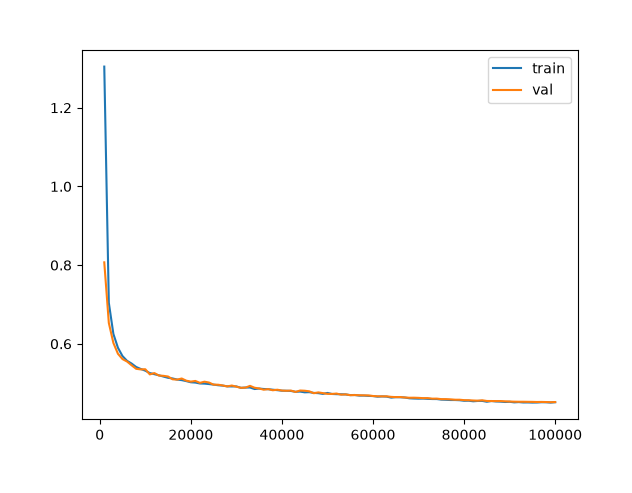

In [5]:
loss_history = np.load(f"{input_dir}{run}/{run}_loss_history.npz")
plt.plot(loss_history['step'], loss_history["train_loss"], label='train')
plt.plot(loss_history['step'], loss_history["val_loss"], label='val')
plt.legend(loc="upper right")
plt.show()

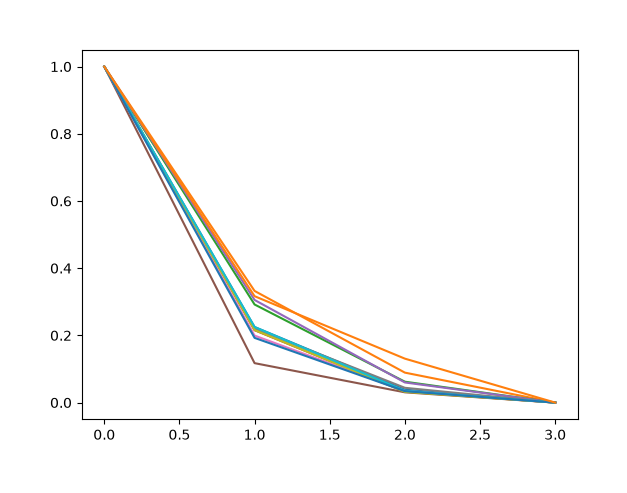

In [6]:
mask_loss = loss_history['mask_loss']
mask_loss -= mask_loss[-1,:]
mask_loss /= mask_loss[0,:]

plt.plot(mask_loss, label=loss_history['mask_names'])
# plt.legend(loc='upper right')
plt.show()

              joint  inputs->dark_matter  inputs->EWino_BF  \
step_100     1.9730               1.9504            1.9695   
step_1000    1.2572               0.6843            0.5974   
step_10000   1.0851               0.2232            0.1520   
step_100000  1.0494               0.0541            0.0316   

             inputs->EWino_mass  inputs->higgs_mass  inputs->squark_mass  \
step_100                 1.9568              2.0001               1.9309   
step_1000                0.4295              0.6292               0.2314   
step_10000               0.0735              0.1445               0.0642   
step_100000              0.0099              0.0263               0.0054   

             dark_matter->inputs  EWino_BF->inputs  EWino_mass->inputs  \
step_100                  1.9787            1.9743              1.9720   
step_1000                 1.4037            1.3988              1.2989   
step_10000                1.2854            1.2685              1.1410   
step_100000 

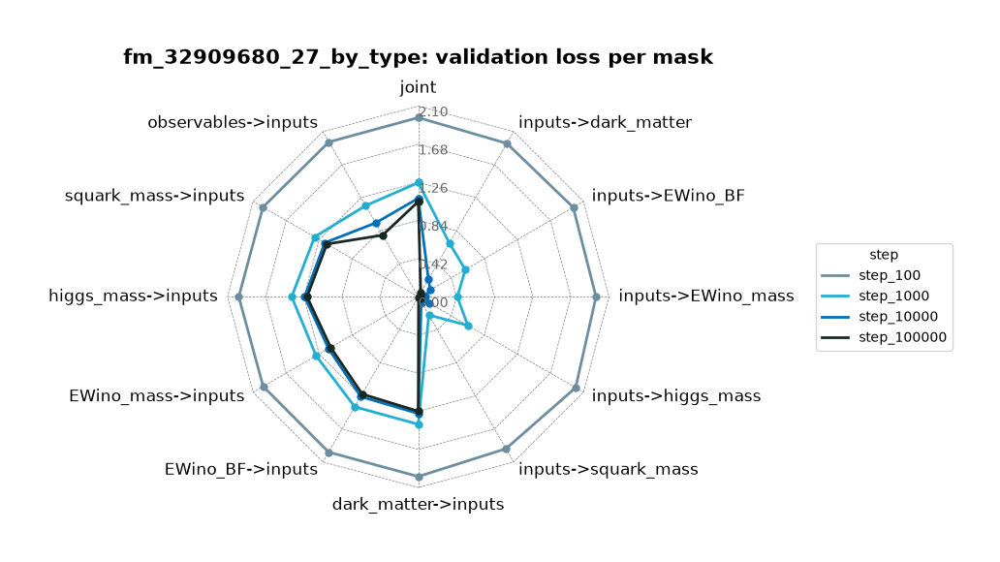

In [22]:
# ---- radar of the per-mask validation loss: one spoke per mask, one polygon per checkpoint step ----
mask_losses = loss_history['mask_loss']   # (n_steps, n_masks), raw losses
short_names = [n.replace("spheno_", "").replace("electroweakino", "EWino").replace("branching_fraction", "BF")
               for n in loss_history['mask_names']]
df = pd.DataFrame(mask_losses, index=[f"step_{s}" for s in loss_history['mask_step']], columns=short_names)
print(df.round(4))

circos = Circos.radar_chart(
    df,
    vmax=np.ceil(mask_losses.max() * 10) / 10,   # the largest loss, rounded up
    fill=False,
    cmap=dict(step_100='#6D8EA0', step_1000='#22AED1', step_10000='#016FB9', step_100000='#182825'),
    marker_size=6,
    bg_color=None,
    grid_interval_ratio=0.2,
    grid_label_formatter=lambda v: f"{v:.2f}",
    line_kws_handler=lambda _: dict(lw=2, ls="solid"),
)
circos.text(f"{run}: validation loss per mask", r=125, size=15, weight="bold")
fig = circos.plotfig()
_ = fig.legend(*circos.ax.get_legend_handles_labels(), loc="center left", bbox_to_anchor=(1.0, 0.5),
               fontsize=10, title="step")   # right of the figure, clear of the spoke labels

## Sampling

In [8]:
# ---- jobs: what the run samples (keyword arguments of generate, see make_job; None = a variable is missing) ----
spec = {
    'joint':                 dict(wanted=r["names"]),                                        # E3
    'inputs_known':          dict(known_from_test=r["inputs"], wanted=r["observables"]),     # E4
    'omega_fixed':           dict(known_fixed={"MO_Omega": omega_0}, wanted=r["inputs"]),    # E5
    'higgs_fixed':           dict(known_fixed={"SP_m_h": m_higgs}, wanted=r["inputs"]),      # E5
    'omega_higgs_fixed':     dict(known_fixed={"MO_Omega": omega_0, "SP_m_h": m_higgs}, wanted=r["inputs"]),  # E5
    'omega_from_ewk':        dict(known_from_test=r["ewk"], wanted=["MO_Omega"] if r["ewk"] else []),    # E6a
    'ewk_given_omega_fixed': dict(known_fixed={"MO_Omega": omega_0}, wanted=r["ewk"]),       # E6b
}
jobs = {name: job | dict(chunk=chunk) for name, s in spec.items() if (job := make_job(r, sel, **s)) is not None}
print(f"sampling jobs: {list(jobs)}")

sampling jobs: ['joint', 'inputs_known', 'omega_fixed', 'higgs_fixed', 'omega_higgs_fixed', 'omega_from_ewk', 'ewk_given_omega_fixed']


In [9]:
# ---- sampling: here ("run"), or hand off to sample_fm.py ("save" -> sbatch -> "load") ----
settings = dict(run=run, final=final, step_size=step_size, n_samples=n_sel, max_test_files=max_test_files,
                omega_0=omega_0, m_higgs=m_higgs)
inputs_path = f"{input_dir}{run}/sampling_inputs.pt"
outputs_path = f"{input_dir}{run}/sampling_outputs.pt"

if sample_mode == "run":   # job i with seed i, as in sample_fm.py
    results = {name: generate(vf, **job, step_size=step_size, seed=i) for i, (name, job) in enumerate(jobs.items())}

elif sample_mode == "save":
    cpu = lambda v: v.cpu() if torch.is_tensor(v) else v
    torch.save({'settings': settings, 'jobs': {name: {k: cpu(v) for k, v in job.items()} for name, job in jobs.items()}},
               inputs_path)
    print(f"saved {inputs_path}")
    raise SystemExit(f"Now sample on a GPU:  sbatch tests/slurm/sample_fm.sbatch {run}\n"
                     f"then set sample_mode = 'load' and run the notebook again.")

elif sample_mode == "load":
    outputs = torch.load(outputs_path, map_location=device)
    if outputs['settings'] != settings:
        raise ValueError(f"{outputs_path} was sampled with {outputs['settings']}, "
                         f"but the notebook uses {settings}. Run 'save' and sample_fm.py again.")
    missing = set(jobs) - set(outputs['results'])
    if missing:
        raise ValueError(f"{outputs_path} has no results for {sorted(missing)}. Resubmit sample_fm.sbatch.")
    results = outputs['results']

else:
    raise ValueError(f"sample_mode must be 'run', 'save' or 'load', not {sample_mode!r}")

## E3. Joint distribution (1D marginals of every variable, 2D of the observables)

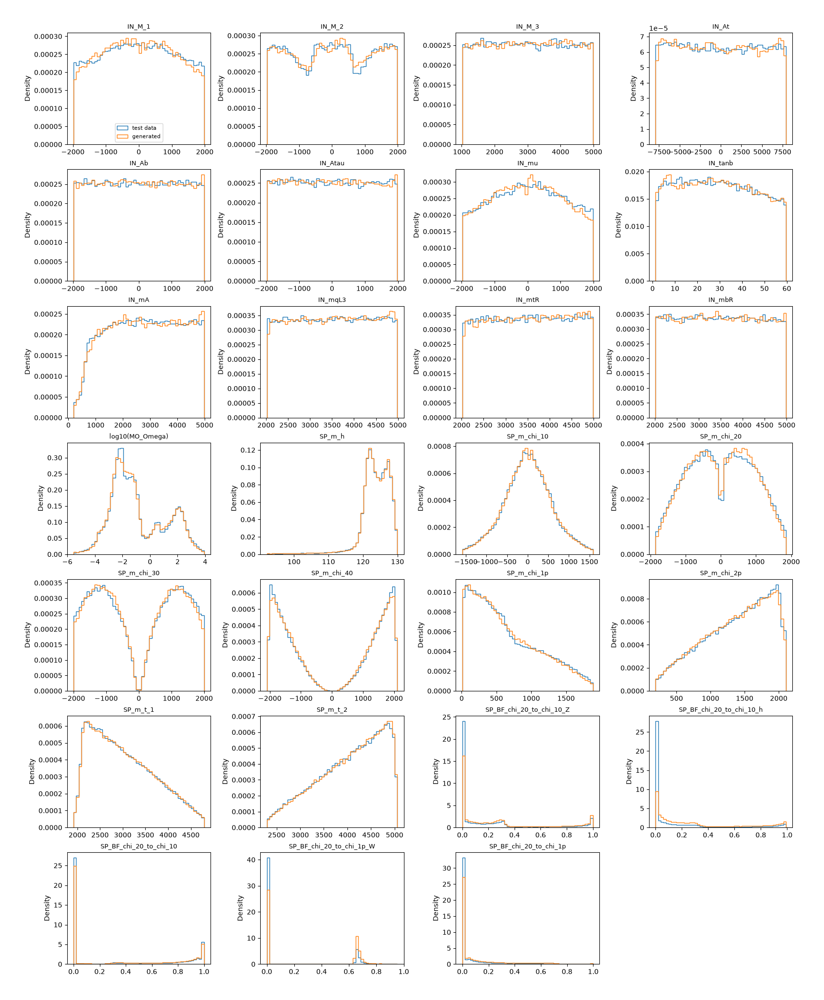

In [10]:
gen_joint = to_physical(r, results['joint'], r["names"])
samples = {"test data": (np.column_stack([truth[n] for n in r["names"]]), r["names"]),
           "generated": (gen_joint, r["names"])}
fig = plot_marginals(samples)

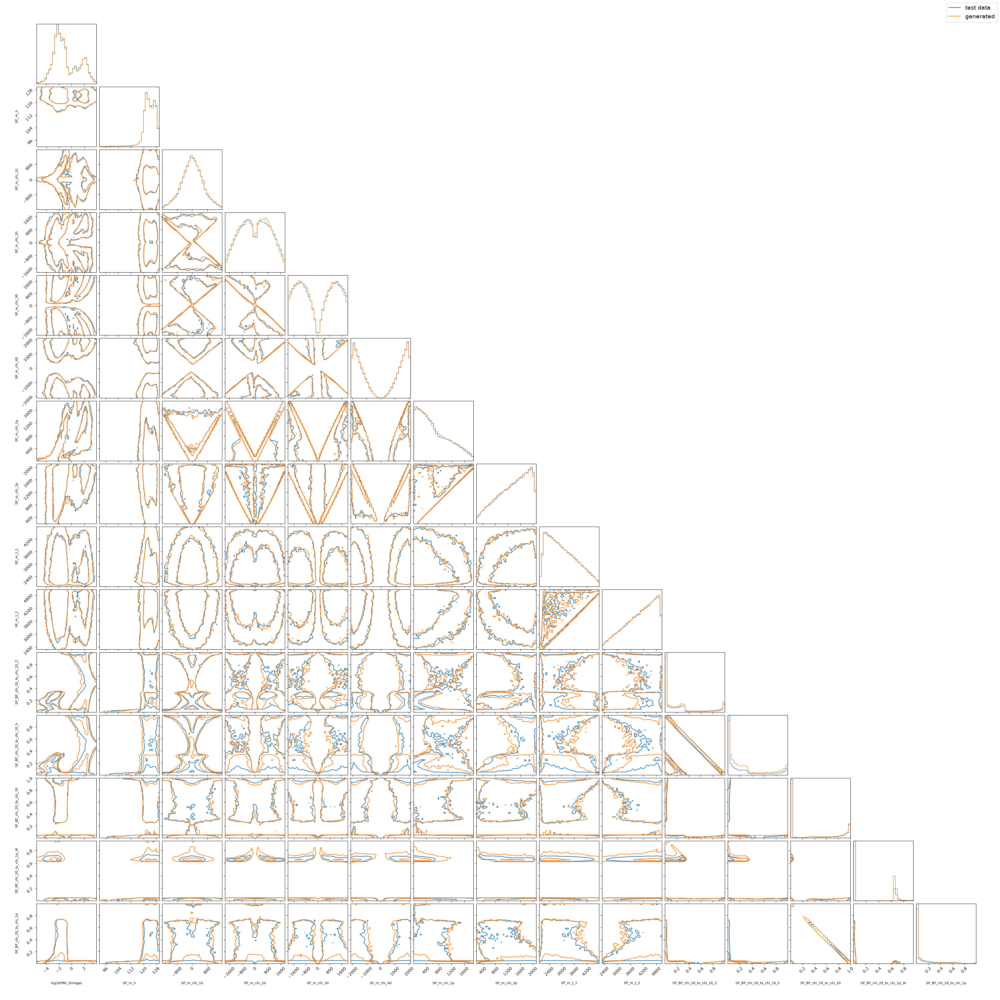

In [11]:
fig = plot_corner(samples, variables=r["observables"])

## E4. Inputs -> observables

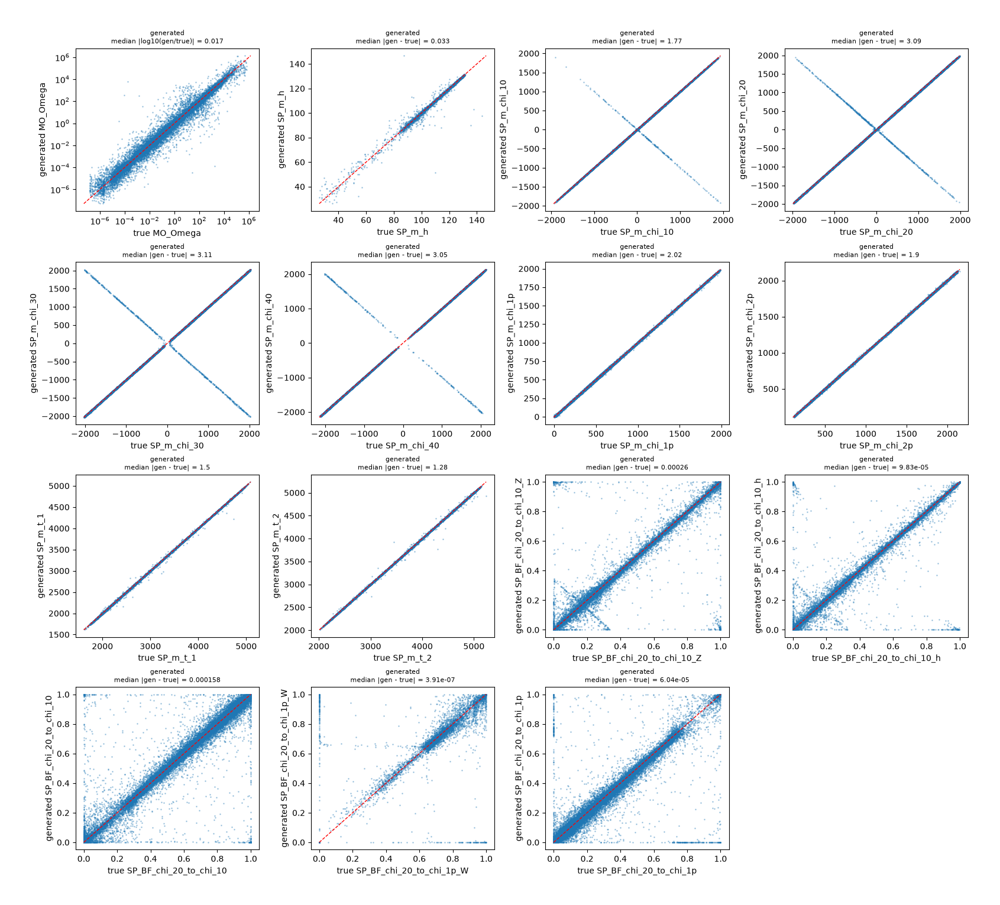

In [12]:
gen_obs = to_physical(r, results['inputs_known'], r["observables"])
pairs = {"generated": (gen_obs, np.column_stack([truth[n] for n in r["observables"]]), r["observables"])}
fig = plot_pred_vs_truth(pairs)

## E5. Inputs given Omega = omega_0, m_h = m_higgs, and both (1D and 2D)

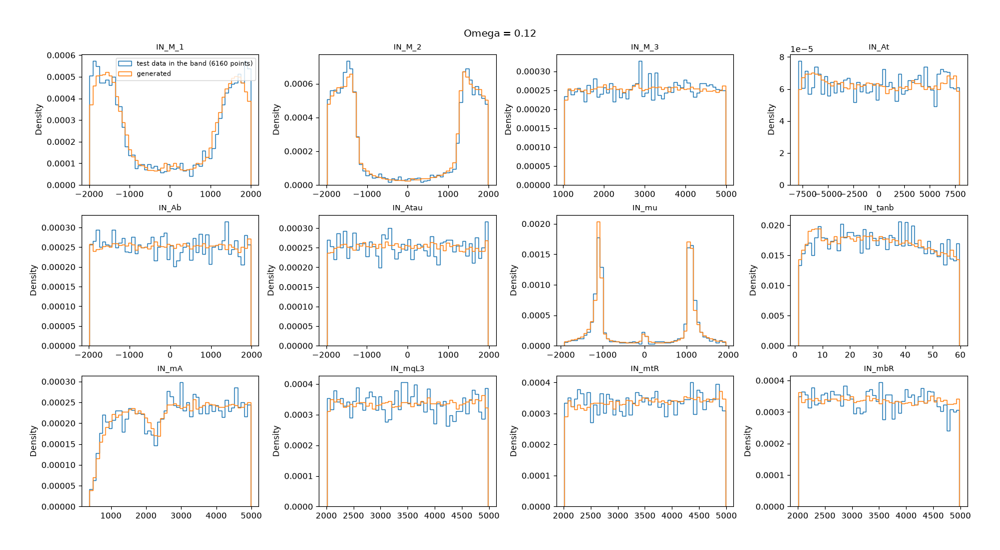

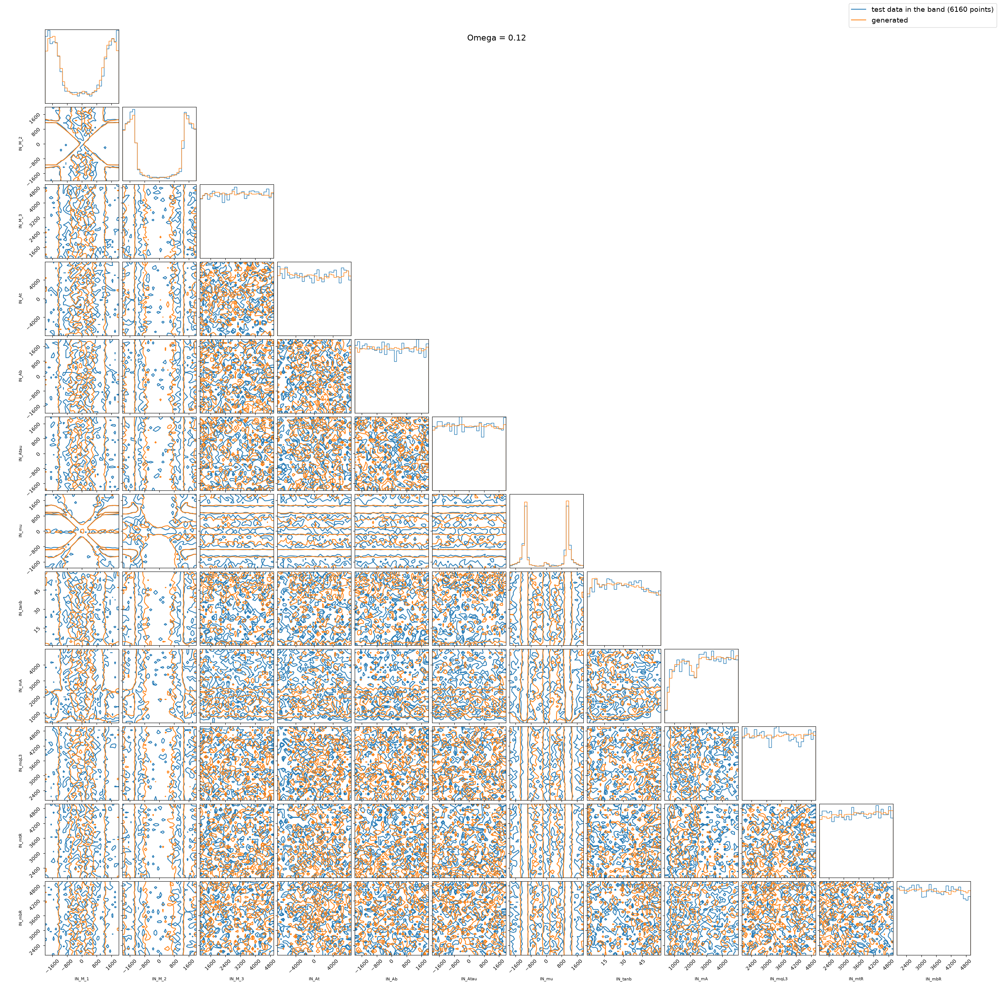

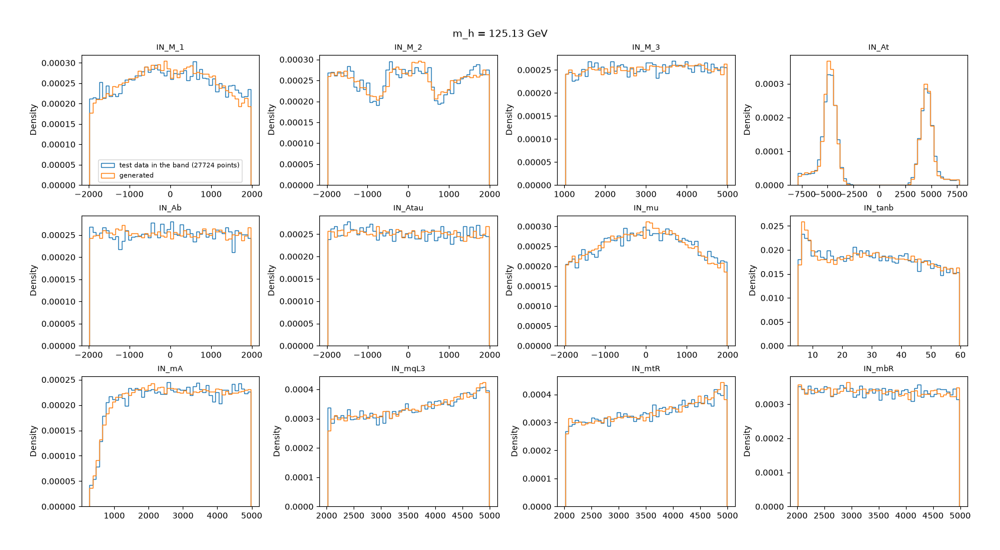

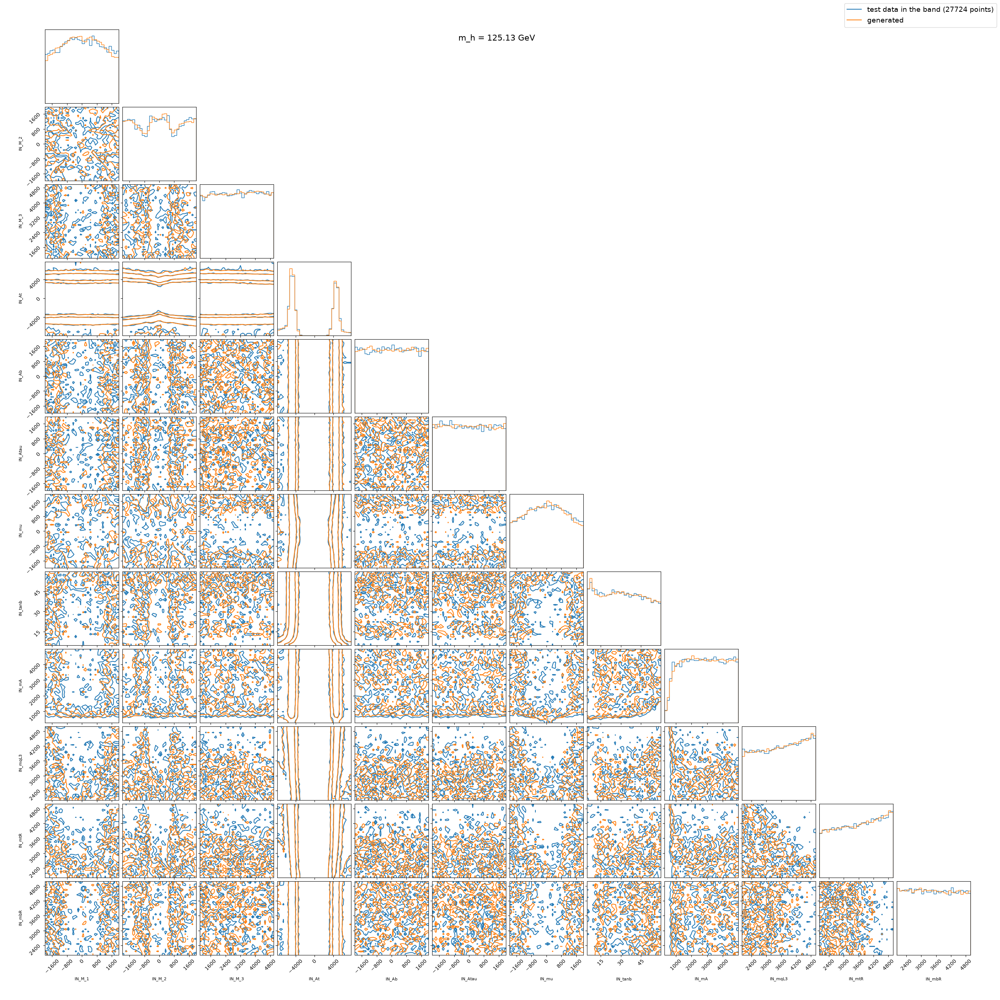

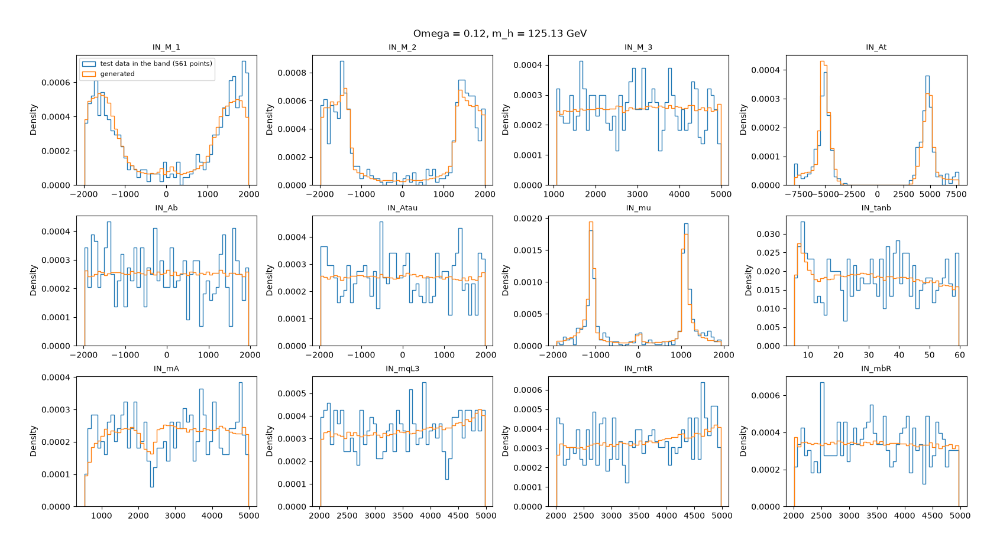

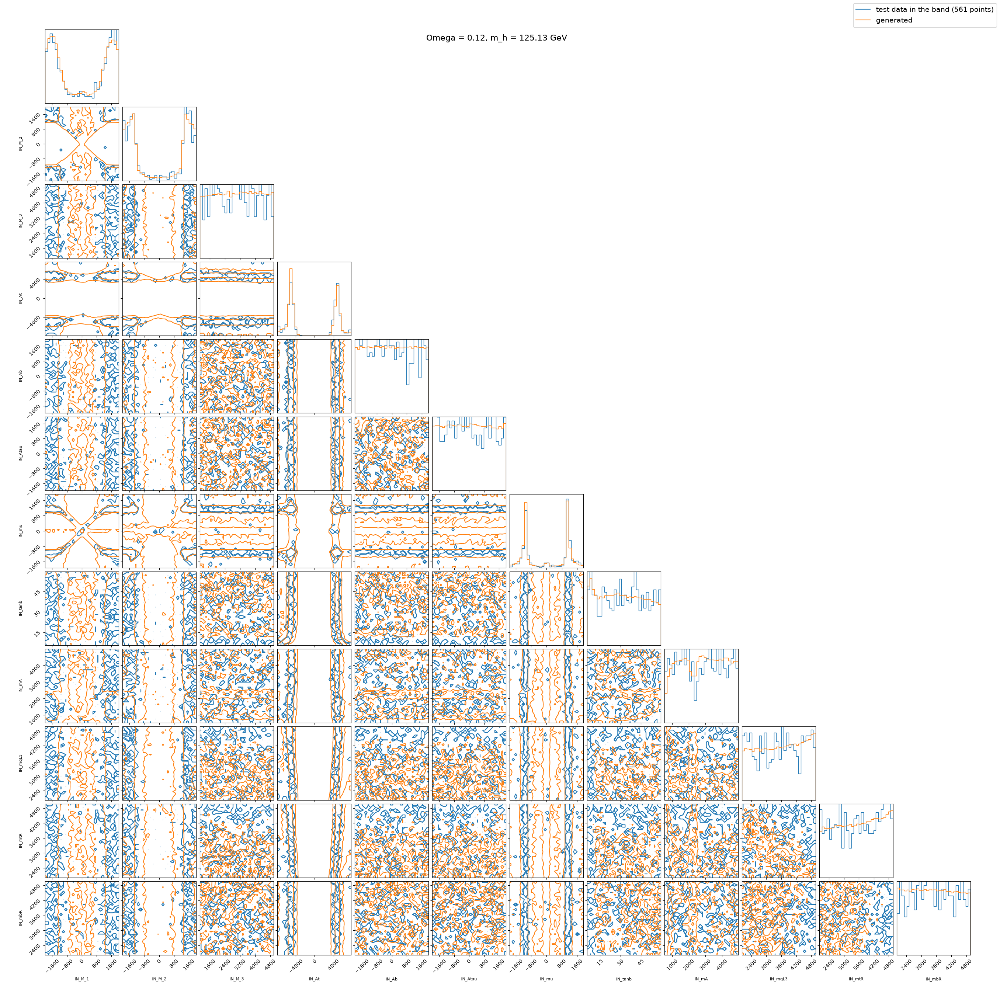

In [13]:
omega_band = np.abs(np.log10(truth_all["MO_Omega"] / omega_0)) < d_log_omega
higgs_band = np.abs(truth_all["SP_m_h"] - m_higgs) < d_m_h if "SP_m_h" in truth_all else None
cases = [("omega_fixed", omega_band, f"Omega = {omega_0}"),
         ("higgs_fixed", higgs_band, f"m_h = {m_higgs} GeV"),
         ("omega_higgs_fixed", None if higgs_band is None else omega_band & higgs_band, f"Omega = {omega_0}, m_h = {m_higgs} GeV")]
min_band = 50   # fewer test points in the band: no plot (too few for the histograms and contours)
figs_e5 = {}    # e.g. save_fig(figs_e5["higgs_fixed_2d"], "E5_higgs_fixed_2d")
for job, band, title in cases:
    if band is None or job not in results:
        continue
    if band.sum() < min_band:
        print(f"{title}: only {band.sum()} test points in the band, skipped")
        continue
    samples = {f"test data in the band ({band.sum()} points)": (np.column_stack([truth_all[n][band] for n in r["inputs"]]), r["inputs"]),
               "generated": (to_physical(r, results[job], r["inputs"]), r["inputs"])}
    figs_e5[job] = plot_marginals(samples)
    figs_e5[job].suptitle(title)
    plt.show()
    figs_e5[f"{job}_2d"] = plot_corner(samples)
    figs_e5[f"{job}_2d"].suptitle(title, fontsize=16)
    plt.show()

## E6. Electroweakino masses and Omega

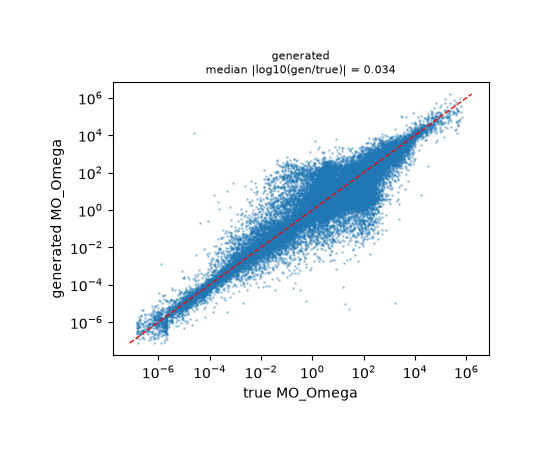

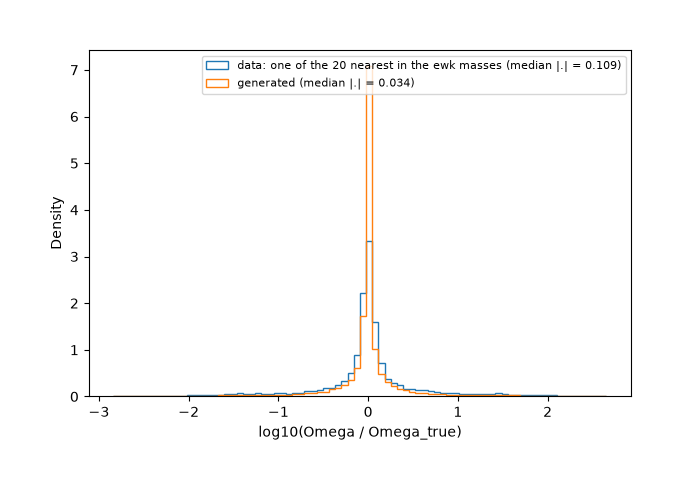

In [14]:
# a) Omega generated from the electroweakino masses (the other variables unknown)
ewk = r["ewk"]
pairs = {"generated": (to_physical(r, results["omega_from_ewk"], ["MO_Omega"]), truth["MO_Omega"][:, None], ["MO_Omega"])}
fig = plot_pred_vs_truth(pairs)
plt.show()

# data spread at fixed electroweakino masses: Omega of one random of the k nearest test points
# in the (standardized) electroweakino masses, compared with the generated Omega
k, n_knn = 20, min(20_000, n_sel)
X = torch.as_tensor(np.column_stack([truth_all[n] for n in ewk]), dtype=torch.float32)
X = (X - X.mean(0)) / X.std(0)
q = torch.as_tensor(sel[:n_knn])
g = torch.Generator().manual_seed(0)
neighbour = torch.empty(n_knn, dtype=torch.long)
for s in range(0, n_knn, 256):
    idx = torch.cdist(X[q[s:s + 256]], X).topk(k + 1, largest=False).indices[:, 1:]   # without the point itself
    neighbour[s:s + 256] = idx[torch.arange(len(idx)), torch.randint(k, (len(idx),), generator=g)]
omega_true = truth_all["MO_Omega"][sel[:n_knn]]
ratios = {f"data: one of the {k} nearest in the ewk masses": np.log10(truth_all["MO_Omega"][neighbour.numpy()] / omega_true),
          "generated": np.log10(pairs["generated"][0][:n_knn, 0] / omega_true)}
fig_spread, ax = plt.subplots(figsize=(7, 4.5))
rng = np.percentile(np.concatenate(list(ratios.values())), [0.5, 99.5])
for name, x in ratios.items():
    ax.hist(x, bins=80, range=rng, density=True, histtype='step', label=f"{name} (median |.| = {np.median(np.abs(x)):.3f})")
ax.set_xlabel("log10(Omega / Omega_true)"); ax.set_ylabel("Density"); ax.legend(fontsize=8)
plt.show()

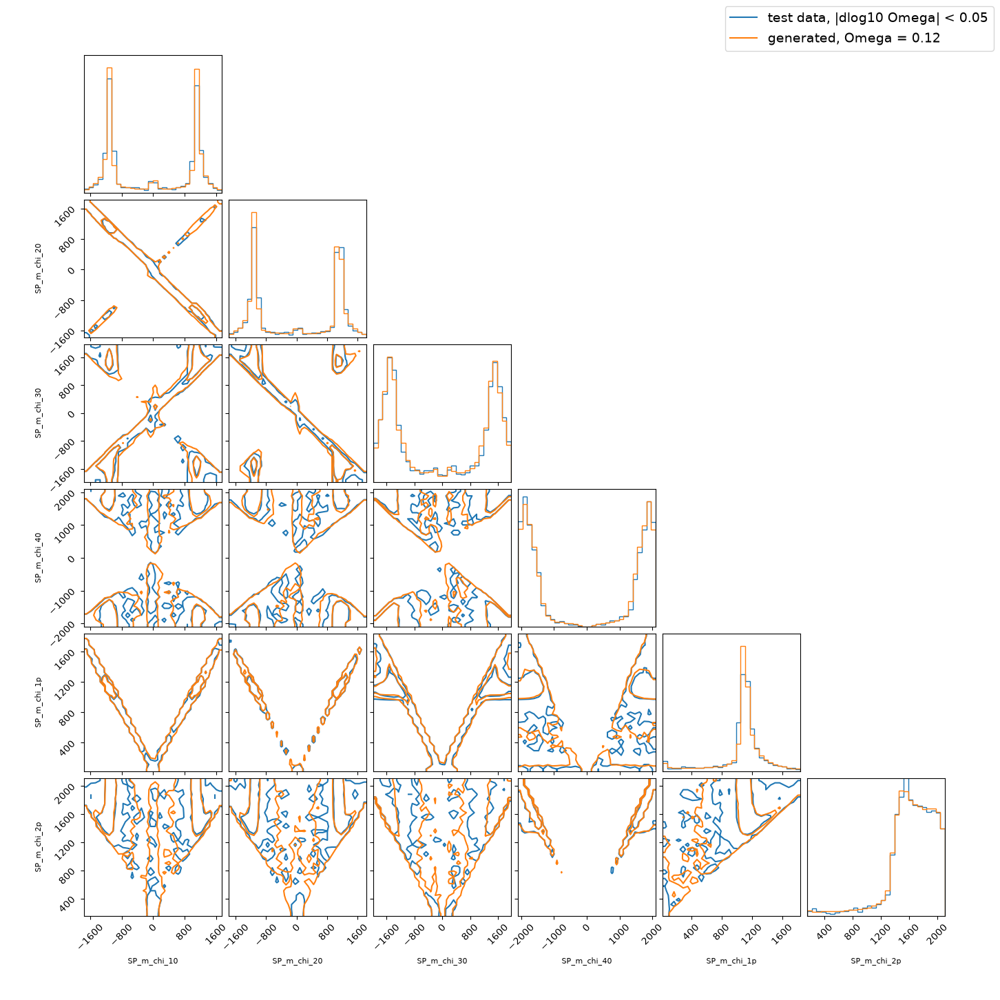

In [15]:
# b) electroweakino masses given Omega = omega_0
samples = {f"test data, |dlog10 Omega| < {d_log_omega}": (np.column_stack([truth_all[n][omega_band] for n in ewk]), ewk),
           f"generated, Omega = {omega_0}": (to_physical(r, results["ewk_given_omega_fixed"], ewk), ewk)}
fig = plot_corner(samples)